<a href="https://colab.research.google.com/github/leejsya/AI_Study/blob/main/HAR/HAR_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#### Library Import

In [ ]:
import random
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [ ]:
SEED = 42

In [ ]:
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

In [ ]:
SIGNAL_NAMES = [
    "body_acc_x",
    "body_acc_y",
    "body_acc_z",

    "body_gyro_x",
    "body_gyro_y",
    "body_gyro_z",

    "total_acc_x",
    "total_acc_y",
    "total_acc_z"
]


CLASS_NAMES = [
    "WALKING",
    "WALKING_UPSTAIRS",
    "WALKING_DOWNSTAIRS",
    "SITTING",
    "STANDING",
    "LAYING"
]

In [ ]:
# signal 데이터를 load하는 function
def load_signals(split):
    signals = [
        np.loadtxt(f"./data/{split}/Inertial_Signals/{names}_{split}.txt", dtype=np.float32) for names in SIGNAL_NAMES
    ]
    return np.stack(signals, axis=-1)

# label 데이터를 load하는 function
def load_labels(split):
    labels = np.loadtxt(f"./data/{split}/y_{split}.txt", dtype=np.int64)
    # 1 ~ 6 -> 0 ~ 5
    return labels - 1

In [ ]:
X_train_full = load_signals("train")
X_test = load_signals("test")

y_train_full = load_labels("train")
y_test = load_labels("test")

In [ ]:
print(f"X_train_full: {X_train_full.shape}")
print(f"X_test: {X_test.shape}")
print()
print(f"y_train_full: {y_train_full.shape}")
print(f"y_test: {y_test.shape}")

X_train_full: (7352, 128, 9)
X_test: (2947, 128, 9)

y_train_full: (7352,)
y_test: (2947,)


In [ ]:
# train/val -> 0.8:0.2, stratify 적용
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.2,
    stratify=y_train_full,
    random_state=SEED,
)

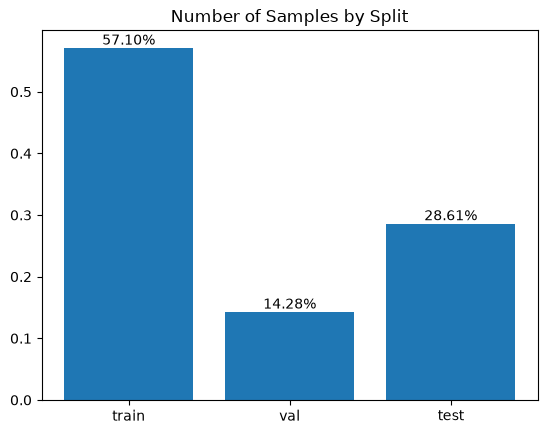

In [ ]:
n_samples = len(y_train) + len(y_val) + len(y_test)
train_prop = len(y_train) / n_samples
val_prop = len(y_val) / n_samples
test_prop = len(y_test) / n_samples
bar1 = plt.bar(['train', 'val', 'test'], [train_prop, val_prop, test_prop])
plt.bar_label(
    bar1,
    labels=[f"{train_prop*100:.2f}%", f"{val_prop*100:.2f}%", f"{test_prop*100:.2f}%"]
)
plt.title("Number of Samples by Split")
plt.show()

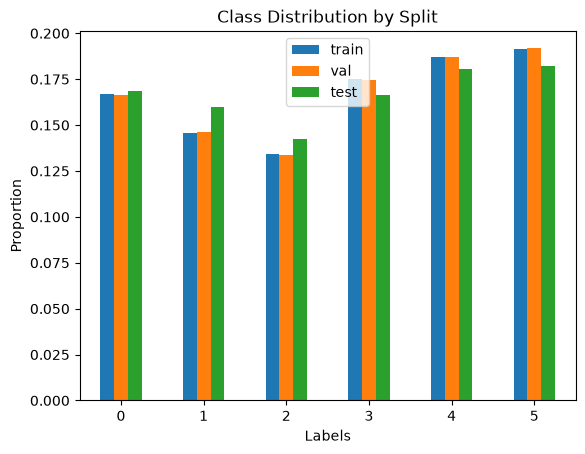

In [ ]:
# stratify가 잘 적용되었는지 split에 따른 클래스 분포 확인
import pandas as pd
labels_dict = {
    'y_train': y_train,
    'y_val': y_val,
    'y_test': y_test,
}
prop_dict = {}
for split in ['train', 'val', 'test']:
    uniques, counts = np.unique(labels_dict[f"y_{split}"], return_counts=True)
    prop_dict[split] = counts/counts.sum()

prop_df = pd.DataFrame(prop_dict)
prop_df.plot.bar(rot=0)
plt.xlabel("Labels")
plt.ylabel("Proportion")
plt.title("Class Distribution by Split")
plt.show()

In [ ]:
scaler = StandardScaler()
# 채널 수
n_channels = X_train.shape[-1]

# StandardScaler는 2차원 배열을 받음
# 따라서 X_train을 2차원으로 reshape한 형태를 객체로 저장
X_train_2d = X_train.reshape(-1, n_channels)

# scaler.fit()
scaler.fit(X_train_2d)

StandardScaler()

In [ ]:
def standardize(X, scaler):
    # 원본 shape 상태를 백업
    original_shape = X.shape

    # scaler fit할 때와 동일하게 2차원으로 reshape
    X_2d = X.reshape(-1, original_shape[-1])
    # scaler 적용
    X_scaled = scaler.transform(X_2d)
    # 원본 shape으로 복원
    X_scaled = X_scaled.reshape(original_shape)

    return X_scaled.astype(np.float32)


In [ ]:
X_train = standardize(X_train, scaler)
X_val = standardize(X_val, scaler)
X_test = standardize(X_test, scaler)

In [ ]:
class HARDataset()

In [ ]:
class HARModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.Conv1 = nn.Conv1d(
            in_channels=9,
            out_channels=64,
            kernel_size=5,
            padding='same'
        )
        self.relu = nn.ReLU()
        self.bn1 = nn.BatchNorm1d(num_features=64)
        self.maxpool = nn.MaxPool1d(kernel_size=2)
        self.dropout = nn.Dropout(0.3)
        self.Conv2 = nn.Conv1d(
            in_channels=64,
            out_channels=128,
            kernel_size=5,
            padding="same",
        )
        self.bn2 = nn.BatchNorm1d(num_features=128)
        self.lstm = nn.LSTM(
            input_size=128,
            hidden_size=128,
        )
        self.linear1 = nn.Linear(
            in_features=128,
            out_features=64,
        )
        self.linear2 = nn.Linear(
            in_features=64,
            out_features=6,
        )
        self.softmax = nn.Softmax()

    def forward(self, x):
        x = self.conv1(x)
        x = self.relu(x)
        x = self.bn1(x)
        x = self.maxpool(x)
        x = self.dropout(x)
        x = self.conv2(x)
        x = self.relu(x)
        x = self.bn2(x)
        x = self.maxpool(x)
        x = self.dropout(x)
        x = self.lstm(x)
        x = self.dropout(x)
        x = self.linear1(x)
        x = self.dropout(x)
        x = self.linear2(x)

        return x


In [ ]:
model = HARModel()
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3)